# Problem komiwojażera – trasa objazdowa 10 Politechnik w Polsce

**Przedmiot:** Laboratorium zastosowań sztucznej inteligencji

**Cel:** Wykorzystując algorytm ewolucyjny, znaleźć najkrótszą trasę zamkniętą, która odwiedza każdą z 10 wybranych politechnik dokładnie raz i wraca do punktu startowego.

**Plan notatnika:**
1. Dane wejściowe – współrzędne politechnik uzyskane z konwersacyjnej AI
2. Macierz odległości (wzór haversine, km)
3. Algorytm ewolucyjny (na podstawie przykładu z zajęć)
4. Wynik i wykres zbieżności
5. Weryfikacja – przegląd zupełny wszystkich tras
6. Wizualizacja najlepszej trasy na mapie

In [1]:
import numpy as np
import sys
import random
import itertools
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()

# Ziarno losowości – dzięki temu wyniki są powtarzalne
random.seed(42)
np.random.seed(42)

## 1. Dane wejściowe

Współrzędne geograficzne (szerokość, długość) głównych budynków politechnik zostały uzyskane z konwersacyjnej AI (Gemini, Google).

Zapytanie: *„Podaj w formacie CSV współrzędne geograficzne głównych budynków 10 politechnik w Polsce:
Warszawskiej, Krakowskiej, Gdańskiej, Wrocławskiej, Śląskiej, Łódzkiej, Poznańskiej,
Lubelskiej, Białostockiej i Rzeszowskiej.
Kolumny: nazwa,miasto,szerokosc,dlugosc (stopnie dziesiętne).
Zwróć wyłącznie dane CSV, bez komentarzy i bez znaczników ```”*

Współrzędne są przybliżone (dokładność ok. kilkuset metrów), co nie ma znaczenia dla odległości rzędu setek kilometrów.

Jeśli zapytanie do AI się nie powiedzie (np. brak klucza API lub połączenia) albo odpowiedź nie przejdzie kontroli (inne kolumny, inna lista miast, współrzędne poza Polską), dane są wczytywane z zapasowego pliku `politechniki_alt.csv`. Niezależnie od źródła politechniki są ustawiane w stałej kolejności, więc indeks 0 to zawsze Politechnika Warszawska.

In [13]:
import io
import pandas as pd

CSV_PATH = "politechniki_alt.csv"   # zapasowe źródło współrzędnych
COLUMNS = ["nazwa", "miasto", "szerokosc", "dlugosc"]
EXPECTED_CITIES = ["Warszawa", "Kraków", "Gdańsk", "Wrocław", "Gliwice",
                   "Łódź", "Poznań", "Lublin", "Białystok", "Rzeszów"]

prompt = """Podaj w formacie CSV współrzędne geograficzne(stopnie dziesiętne, z dokładnością do 6 miejsc po przecinku) głównych budynków 10 politechnik w Polsce:
            Warszawskiej, Krakowskiej, Gdańskiej, Wrocławskiej, Śląskiej, Łódzkiej, Poznańskiej,
            Lubelskiej, Białostockiej i Rzeszowskiej, zaczynajc od politechniki w Warszawie.
            Kolumny: nazwa,miasto,szerokosc,dlugosc.
            Zwróć wyłącznie dane CSV, bez komentarzy i bez znaczników ```."""


def from_gemini():
    from google import genai
    from google.genai import types
    client = genai.Client()  # klucz API ze zmiennej środowiskowej GOOGLE_API_KEY (lub pliku .env)
    response = client.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt,
        config=types.GenerateContentConfig(temperature=0),
    )
    tekst = response.text.replace("```csv", "").replace("```", "").strip()  # na wszelki wypadek usuwamy znaczniki ```
    df = pd.read_csv(io.StringIO(tekst))
    df.columns = df.columns.str.strip()
    return df


def validate(df):
    # zwraca listę problemów; pusta lista = dane poprawne
    problems = []
    if list(df.columns) != COLUMNS:
        return [f"nieprawidłowe kolumny: {list(df.columns)}"]
    if sorted(df["miasto"].str.strip()) != sorted(EXPECTED_CITIES):
        problems.append(f"nieprawidłowa lista miast: {df['miasto'].tolist()}")
    if not (df["szerokosc"].between(49.0, 55.0).all() and df["dlugosc"].between(14.0, 24.2).all()):
        problems.append("współrzędne poza granicami Polski")
    return problems


# Źródło główne: AI; jeśli zapytanie się nie uda lub odpowiedź jest błędna -> plik CSV
try:
    df = from_gemini()
    problems = validate(df)
except Exception as e:
    problems = [f"błąd zapytania do AI: {e}"]

if problems:
    print("Problemy z danymi z AI:", problems, file=sys.stderr)
    df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

names  = df["nazwa"].tolist()
cities = df["miasto"].tolist()
points = list(zip(df["szerokosc"], df["dlugosc"]))
no_of_points = len(points)

Problemy z danymi z AI: ["błąd zapytania do AI: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}"]


## 2. Macierz odległości

Używamy **wzoru haversine**, ponieważ mamy współrzędne geograficzne (stopnie) – liczy on odległość po powierzchni kuli ziemskiej (w linii prostej, „w linii lotu ptaka”), w kilometrach.

$$d = 2R \cdot \arcsin\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\Delta\lambda}{2}}$$

gdzie $R = 6371$ km to promień Ziemi, $\varphi$ – szerokość, $\lambda$ – długość geograficzna (w radianach).

In [3]:
def haversine(p1, p2):
    R = 6371.0  # promień Ziemi w km
    lat1, lon1 = np.radians(p1)
    lat2, lon2 = np.radians(p2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

distances = np.zeros((no_of_points, no_of_points))

for i in range(no_of_points):
    for j in range(no_of_points):
        if i != j:
            distances[i][j] = haversine(points[i], points[j])

np.set_printoptions(precision=0, suppress=True, linewidth=150)
print("Macierz odległości [km]:")
print(distances)

Macierz odległości [km]:
[[  0. 250. 287. 299. 269. 119. 277. 152. 175. 255.]
 [250.   0. 487. 234.  93. 189. 333. 225. 404. 148.]
 [287. 487.   0. 378. 454. 297. 245. 437. 329. 536.]
 [299. 234. 378.   0. 146. 181. 144. 383. 472. 370.]
 [269.  93. 454. 146.   0. 171. 264. 292. 440. 240.]
 [119. 189. 297. 181. 171.   0. 186. 222. 293. 263.]
 [277. 333. 245. 144. 264. 186.   0. 406. 424. 441.]
 [152. 225. 437. 383. 292. 222. 406.   0. 213. 140.]
 [175. 404. 329. 472. 440. 293. 424. 213.   0. 353.]
 [255. 148. 536. 370. 240. 263. 441. 140. 353.   0.]]


## 3. Algorytm ewolucyjny

Funkcje:

- **Osobnik (chromosom)** – permutacja numerów politechnik, np. `[3, 0, 7, ...]` oznacza trasę 3 → 0 → 7 → ... → powrót do 3.
- **Funkcja oceny (`fitness`)** – długość trasy w km (minimalizujemy).
- **Selekcja (`select`)** – ruletka: prawdopodobieństwo wyboru jest odwrotnie proporcjonalne do długości trasy, więc krótsze trasy częściej przechodzą dalej.
- **Mutacja (`mutate`)** – odwrócenie losowego fragmentu trasy (inwersja).
- **Krzyżowanie (`cross`)** – fragment trasy od jednego rodzica, pozostałe miasta w kolejności z drugiego rodzica (żadne miasto się nie powtarza).

In [4]:
def create_initial_population(size, no_of_points):
    population = []
    for i in range(size):
        chromosome = np.random.permutation(no_of_points)
        population.append(chromosome)
    return population


def fitness(x, distances):
    # długość trasy zamkniętej (z powrotem do punktu startowego)
    distance = 0
    for i in range(len(x) - 1):
        distance = distance + distances[x[i]][x[i + 1]]
    distance = distance + distances[x[-1]][x[0]]
    return distance


def mutate(x, mutation_prob):
    # inwersja losowego fragmentu trasy
    xp = x.copy()
    size = len(xp)
    if random.uniform(0, 1) <= mutation_prob:
        start, end = sorted([random.randrange(size) for _ in range(2)])
        xp[start:end + 1] = xp[start:end + 1][::-1]
    return xp


def cross(xs, crossover_prob):
    par1 = xs[0]
    par2 = xs[1]
    size = len(par1)
    if random.uniform(0, 1) <= crossover_prob:
        ch1, ch2 = [-1] * size, [-1] * size
        start, end = sorted([random.randrange(size) for _ in range(2)])
        # fragment przepisany bez zmian od rodzica
        for i in range(start, end + 1):
            ch1[i] = par1[i]
            ch2[i] = par2[i]
        # pozostałe miejsca uzupełniane w kolejności z drugiego rodzica
        for i in range(size):
            if ch1[i] == -1:
                for j in range(size):
                    if par2[j] not in ch1:
                        ch1[i] = par2[j]
                        break
        for i in range(size):
            if ch2[i] == -1:
                for j in range(size):
                    if par1[j] not in ch2:
                        ch2[i] = par1[j]
                        break
        return (np.array(ch1), np.array(ch2))
    else:
        return xs


def evaluate(population, distances):
    evaluations = [fitness(x, distances) for x in population]
    evaluations = [i if i != 0 else 0.01 for i in evaluations]
    return evaluations


def select(population, evaluations):
    # selekcja ruletkowa: krótsza trasa -> większe prawdopodobieństwo
    probabilities = np.array(evaluations) / sum(evaluations)
    probabilities = 1.0 / probabilities
    probabilities = probabilities / probabilities.sum()
    selection = np.random.choice(a=range(population.shape[0]),
                                 size=int(population.shape[0] / 2),
                                 replace=False, p=probabilities)
    return population[selection]


def create_next_generation(selected, population_size, mutation_prob, crossover_prob):
    next_generation = list()
    # mutanci
    for i in range(selected.shape[0]):
        next_generation.append(mutate(selected[i], mutation_prob))
    # potomkowie z krzyżowania
    for i in range(selected.shape[0]):
        selection = np.random.choice(a=range(selected.shape[0]), size=2, replace=False)
        crossed = cross(tuple(selected[selection]), crossover_prob)
        next_generation.append(crossed[0])
        next_generation.append(crossed[1])
    selection2 = np.random.choice(a=range(len(next_generation)), size=population_size, replace=False)
    return np.array([next_generation[index] for index in selection2])

### Parametry algorytmu

W przykładzie populacja miała tylko 10 osobników i 5 punktów. Dla 10 politechnik zwiększamy populację do 100 osobników.

In [5]:
population_size = 100     # liczba osobników w populacji
no_of_generations = 2000  # liczba pokoleń
mutation_prob = 0.5       # prawdopodobieństwo mutacji
crossover_prob = 0.3      # prawdopodobieństwo krzyżowania

### Uruchomienie algorytmu

In [6]:
population = create_initial_population(population_size, no_of_points)

min_evaluation = sys.float_info.max
min_evaluation_history = list()
best_generation = 0

for i in range(no_of_generations):
    evaluations = evaluate(population, distances)

    if min(evaluations) < min_evaluation:
        min_evaluation = min(evaluations)
        best_solution = population[np.argmin(evaluations)].copy()
        best_generation = i

    selected = select(np.array(population), evaluations)
    population = create_next_generation(selected, population_size, mutation_prob, crossover_prob)

    min_evaluation_history.append(min_evaluation)

print(f"Najlepsza trasa znaleziona w pokoleniu: {best_generation}")
print(f"Długość najlepszej trasy: {min_evaluation:.1f} km")

Najlepsza trasa znaleziona w pokoleniu: 42
Długość najlepszej trasy: 1721.3 km


## 4. Wynik

In [7]:
# Obracamy trasę tak, aby zaczynała się od Politechniki Warszawskiej (indeks 0)
start = list(best_solution).index(0)
best_route = list(best_solution[start:]) + list(best_solution[:start])

print("Najlepsza trasa objazdowa:\n")
total = 0
for k in range(len(best_route)):
    a = best_route[k]
    b = best_route[(k + 1) % len(best_route)]
    d = distances[a][b]
    total += d
    print(f"{k+1:2d}. {cities[a]:10s} -> {cities[b]:10s} {d:6.1f} km   (razem {total:7.1f} km)")

print(f"\nŁączna długość trasy: {total:.1f} km")

Najlepsza trasa objazdowa:

 1. Warszawa   -> Białystok   175.2 km   (razem   175.2 km)
 2. Białystok  -> Lublin      213.1 km   (razem   388.3 km)
 3. Lublin     -> Rzeszów     140.5 km   (razem   528.8 km)
 4. Rzeszów    -> Kraków      147.9 km   (razem   676.7 km)
 5. Kraków     -> Gliwice      93.3 km   (razem   770.0 km)
 6. Gliwice    -> Wrocław     145.8 km   (razem   915.8 km)
 7. Wrocław    -> Poznań      144.4 km   (razem  1060.2 km)
 8. Poznań     -> Gdańsk      245.1 km   (razem  1305.4 km)
 9. Gdańsk     -> Łódź        297.1 km   (razem  1602.5 km)
10. Łódź       -> Warszawa    118.8 km   (razem  1721.3 km)

Łączna długość trasy: 1721.3 km


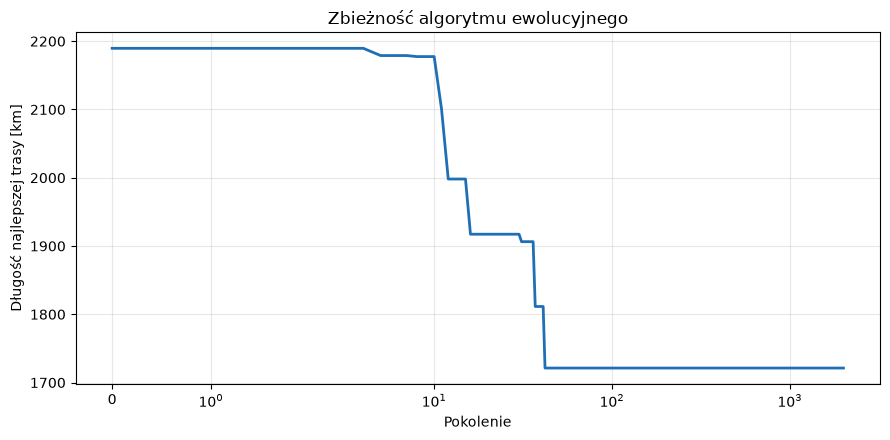

In [8]:
plt.figure(figsize=(9, 4.5))
plt.plot(min_evaluation_history, color="#1f6fb4", linewidth=2)
plt.title("Zbieżność algorytmu ewolucyjnego")
plt.xlabel("Pokolenie")
plt.ylabel("Długość najlepszej trasy [km]")
plt.grid(alpha=0.3)
plt.xscale("symlog")  # skala logarytmiczna – lepiej widać pierwsze pokolenia
plt.tight_layout()
plt.savefig("zbieznosc.png")
plt.show()

## 5. Weryfikacja – przegląd zupełny

Dla 10 miast liczba różnych tras zamkniętych wynosi $\frac{(10-1)!}{2} = 181\,440$, więc można je wszystkie sprawdzić i porównać wynik algorytmu z prawdziwym optimum. Dla większej liczby miast (np. 20 → ok. $6 \cdot 10^{16}$ tras) byłoby to niemożliwe – i właśnie wtedy przydają się algorytmy ewolucyjne.

In [9]:
best_bf = sys.float_info.max
best_bf_route = None

# Ustalamy miasto startowe (0), permutujemy pozostałe 9
for perm in itertools.permutations(range(1, no_of_points)):
    route = (0,) + perm
    d = fitness(route, distances)
    if d < best_bf:
        best_bf = d
        best_bf_route = route

print(f"Optimum (przegląd zupełny): {best_bf:.1f} km")
print(f"Algorytm ewolucyjny:        {min_evaluation:.1f} km")
print("Trasa optymalna:", " -> ".join(cities[i] for i in best_bf_route))

if abs(best_bf - min_evaluation) < 1e-6:
    print("\nAlgorytm ewolucyjny znalazł trasę optymalną ✔")
else:
    print(f"\nRóżnica: {(min_evaluation / best_bf - 1) * 100:.2f}% powyżej optimum")

Optimum (przegląd zupełny): 1721.3 km
Algorytm ewolucyjny:        1721.3 km
Trasa optymalna: Warszawa -> Białystok -> Lublin -> Rzeszów -> Kraków -> Gliwice -> Wrocław -> Poznań -> Gdańsk -> Łódź

Algorytm ewolucyjny znalazł trasę optymalną ✔


## 6. Wizualizacja najlepszej trasy

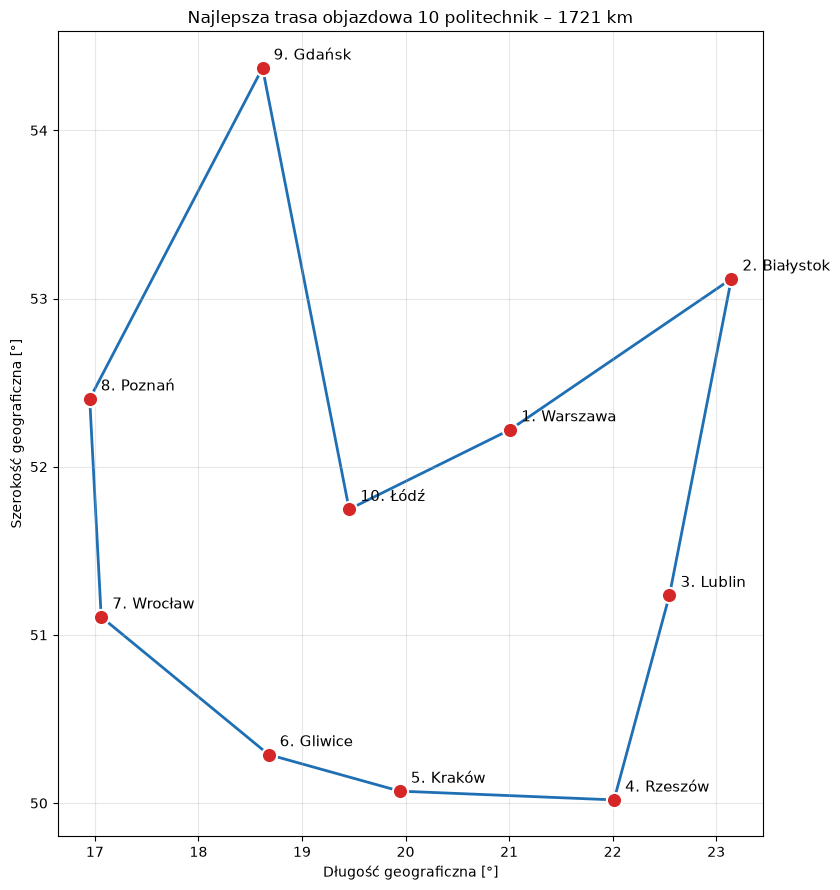

In [10]:
lats = [points[i][0] for i in best_route] + [points[best_route[0]][0]]
lons = [points[i][1] for i in best_route] + [points[best_route[0]][1]]

fig, ax = plt.subplots(figsize=(9, 9))
ax.plot(lons, lats, "-", color="#1f6fb4", linewidth=2, zorder=1)
ax.scatter([p[1] for p in points], [p[0] for p in points], s=120,
           color="#d62728", edgecolor="white", linewidth=1.5, zorder=2)

for k, i in enumerate(best_route):
    ax.annotate(f"{k+1}. {cities[i]}", (points[i][1], points[i][0]),
                textcoords="offset points", xytext=(8, 6), fontsize=11)

ax.set_title(f"Najlepsza trasa objazdowa 10 politechnik – {min_evaluation:.0f} km")
ax.set_xlabel("Długość geograficzna [°]")
ax.set_ylabel("Szerokość geograficzna [°]")
ax.set_aspect(1 / np.cos(np.radians(52)))  # korekta proporcji dla szerokości Polski
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("trasa.png")
plt.show()

### Interaktywna mapa (folium)

In [11]:
import folium

m = folium.Map(location=[52.0, 19.4], zoom_start=6, tiles="OpenStreetMap")

route_coords = [points[i] for i in best_route] + [points[best_route[0]]]
folium.PolyLine(route_coords, color="#1f6fb4", weight=4, opacity=0.8).add_to(m)

for k, i in enumerate(best_route):
    folium.Marker(
        location=points[i],
        popup=f"{k+1}. {names[i]}",
        tooltip=f"{k+1}. {cities[i]}",
        icon=folium.DivIcon(html=f'''
            <div style="background:#d62728;color:white;border-radius:50%;
                        width:26px;height:26px;line-height:26px;text-align:center;
                        font-weight:bold;font-size:13px;border:2px solid white;">{k+1}</div>''')
    ).add_to(m)

m

## Wnioski

- Algorytm ewolucyjny znalazł trasę objazdową 10 politechnik i – jak pokazał przegląd zupełny – jest ona optymalna (dla odległości w linii prostej).
- Wykres zbieżności pokazuje, że algorytm szybko poprawia rozwiązanie w pierwszych pokoleniach, a potem długość trasy się stabilizuje.
- Odległości liczono w linii prostej (haversine). Rzeczywista trasa drogowa byłaby dłuższa (zwykle o 20–30%), a jej kolejność mogłaby się nieznacznie różnić.
- Dla 10 miast przegląd zupełny jest jeszcze możliwy, ale dla kilkudziesięciu miast liczba tras rośnie silniowo – wtedy algorytm ewolucyjny jest praktycznym sposobem na znalezienie dobrego rozwiązania w rozsądnym czasie.